# Prime clocks: how far must the clocks run?

Measures the three predictions M1, M2 and M3 of the section "The measurement: how far must the
clocks run?" in [`docs/connections/riemann-hypothesis.md`](../../docs/connections/riemann-hypothesis.md).
The predictions, the thresholds, the radius 0.3, the 40 targets per N and the stop rule at height
5,000,000 are in the note, which was pushed before this notebook was run. The seed
(`default_rng(0)`, drawn in the order N = 2, 3, 4, 5), the 12 heights for M1 and the least-squares
fit were set in the helper's brief before the run, and are not in the pushed note. None of these
is changed here. A prediction that fails prints a line starting with
`[FAIL]` and the notebook still runs to the end. Checks that the measurement itself is valid
(step halving, grid refinement, an independent sampled check) are asserted: they stop the notebook.

**The model.** There is no learned model. The clock of the prime `p` at height `t` is the angle
`t * log(p)` taken round the circle. For `N` primes the clocks together are a point on a torus with
`N` angles, and growing `t` draws a straight line on it. The distance between two points of the
torus is the straight-line distance between the `N` angles, each difference wrapped into
`(-pi, pi]`. There is no output axis and no loss here, so there is no vertical error to report next
to the distance. Where a nearest point is reported, the largest single-clock error at that point is
printed beside the distance.

**Measured and from the formula.** A number is "measured" if it came out of the search below. The
volume estimate and `pi * sqrt(0.2)` are "from the formula".

In [1]:
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.spatial import cKDTree

ROOT = next(folder for folder in [Path.cwd(), *Path.cwd().parents] if (folder / "CLAUDE.md").exists())
sys.path.insert(0, str(ROOT / "experiments" / "part1"))
from common import use_style, NEAREST, VERTICAL, BOUND, MODEL, BEFORE  # sets torch's default dtype; unused here

use_style()

TWO_PI = 2.0 * math.pi
PRIMES = (2, 3, 5, 7, 11)
LOG_PRIMES = np.log(np.array(PRIMES, dtype=float))
LOG_TWO, LOG_THREE = float(LOG_PRIMES[0]), float(LOG_PRIMES[1])
LINE_SPEED_SQUARED = LOG_TWO ** 2 + LOG_THREE ** 2
SLOPE_RATIO = LOG_TWO / LOG_THREE        # how far the clock of 2 moves while the clock of 3 turns once, in turns

HIT_RADIUS = 0.3                         # M3: a hit is a torus distance of at most this
TARGETS_PER_COUNT = 40                   # M3: random targets for each number of primes
HEIGHT_LIMIT = 5_000_000                 # stop rule: no height above this is searched
SEED = 0                                 # numpy default_rng(SEED) draws every M3 target, N = 2, 3, 4, 5 in order
FIGURE_PATH = ROOT / "graphs" / "prime_clocks.png"

VERDICTS = {}


def wrap_angle(angle):
    """Wrap each angle difference into (-pi, pi]."""
    return angle - TWO_PI * np.round(angle / TWO_PI)


def get_torus_distance(first_point, second_point):
    return np.linalg.norm(wrap_angle(first_point - second_point), axis=-1)


def check(condition, text, stop=True):
    """A validity check that can fail. It stops the notebook when it fails (unless stop is False)."""
    print(("[PASS] check: " if condition else "[FAIL] check: ") + text)
    assert condition or not stop, text


def note_by_construction(text):
    """A line that holds because of how the code is written. It is not evidence and is not counted."""
    print("[by construction, cannot fail] " + text)


def give_verdict(name, passed, text):
    """A prediction. It never stops the notebook: a failure is printed and kept for the summary."""
    VERDICTS[name] = passed
    print(("[PASS] " if passed else "[FAIL] ") + text)

## M1: two clocks, the rate

`gap(T)` is the largest distance from any point of the 2-torus to the line
`{(t log 2, t log 3) mod 2 pi : 0 <= t <= T}`. **Prediction (fixed, written before the run):** the
fitted slope of `log gap` against `log T`, for 12 values of `T` spaced evenly in log from 30 to
30,000, is between -1.3 and -0.7. **It counts against the prediction** if the slope is outside that
range.

**How `gap(T)` is computed, exactly.** Cut the line each time the clock of 3 completes a turn. Each
piece is a straight segment that crosses the square `[0, 2 pi)^2` from the bottom edge to the top
edge, and all pieces have the same direction. The distance from a point to the line is the exact
point-to-segment distance to the nearest piece, looked up through the sorted start positions of the
pieces, with the point copied one square up and one square down so that the line is followed across
the edge. The largest distance is searched on a full grid of the torus, on a fine grid inside the
largest gaps between neighbouring pieces and around the end of the line, and each best point is
refined by repeated zooming. No sampling step of the line is involved.

Checks that can fail (asserted): (1) the distance function against an independent one that samples
the line finely and uses a periodic k-d tree (heights 30 and 300, step halved); (2) the gap found by
sampling at heights 30, 105.3 and 369.9 when the step is halved and the torus grid is refined;
(3) at T = 2433.4 and T = 30000, where sampling the line is too expensive, a brute-force distance
over every piece (no sorted lookup) at the reported farthest point, on a fine local grid around it, at
500 random torus points and at 300 random points inside the 100 widest gaps between neighbouring
pieces. The "doubled settings" column only reruns the same search with finer settings and is labelled
as not evidence.

In [2]:
def list_start_offsets(height):
    """Start height and start position (angle of the clock of 2) of each piece of the line."""
    crossings = int(np.floor(height * LOG_THREE / TWO_PI))
    start_heights = TWO_PI * np.arange(crossings + 1) / LOG_THREE
    return start_heights, np.mod(LOG_TWO * start_heights, TWO_PI)


def make_pieces(height):
    start_heights, start_offsets = list_start_offsets(height)
    lengths = np.minimum(TWO_PI / LOG_THREE, height - start_heights)     # in units of height
    order = np.argsort(start_offsets)
    return start_offsets[order], lengths[order]


def get_distance_to_line(points_x, points_y, pieces, neighbours=3):
    """Exact distance from torus points to the line. points_x is the angle of the clock of 2."""
    offsets, lengths = pieces
    count = offsets.size
    points_y = np.mod(points_y, TWO_PI)
    best = np.full(points_x.shape, np.inf)
    for shift in (-TWO_PI, 0.0, TWO_PI):
        height_angle = points_y + shift
        cross_position = np.mod(points_x - SLOPE_RATIO * height_angle, TWO_PI)
        insert_position = np.searchsorted(offsets, cross_position)
        for step in range(-neighbours, neighbours):
            index = (insert_position + step) % count
            sideways = SLOPE_RATIO * height_angle
            shifted = wrap_angle(points_x - offsets[index] - sideways) + sideways
            along = (shifted * LOG_TWO + height_angle * LOG_THREE) / LINE_SPEED_SQUARED
            along = np.clip(along, 0.0, lengths[index])
            distance = np.hypot(shifted - along * LOG_TWO, height_angle - along * LOG_THREE)
            best = np.minimum(best, distance)
    return best


def list_largest_gaps(offsets, count):
    ordered = np.sort(offsets)
    gaps = np.diff(np.append(ordered, ordered[0] + TWO_PI))
    top = np.argsort(gaps)[::-1][:count]
    return ordered[top], gaps[top]


def refine_maximum(start_x, start_y, pieces, neighbours, rounds=14):
    """Zoom in on a local maximum of the distance by repeated 21 by 21 grids."""
    best_x, best_y = start_x, start_y
    best_value = get_distance_to_line(np.array([best_x]), np.array([best_y]), pieces, neighbours)[0]
    half_width = 0.5 * best_value
    axis = np.linspace(-1.0, 1.0, 21)
    for _ in range(rounds):
        grid_x, grid_y = np.meshgrid(best_x + half_width * axis, best_y + half_width * axis)
        values = get_distance_to_line(grid_x.ravel(), grid_y.ravel(), pieces, neighbours)
        winner = int(np.argmax(values))
        if values[winner] > best_value:
            best_value = float(values[winner])
            best_x, best_y = float(grid_x.ravel()[winner]), float(grid_y.ravel()[winner])
        half_width *= 0.5
    return best_value, best_x, best_y


def find_gap(height, refinement=1, neighbours=3):
    return find_gap_and_point(height, refinement, neighbours)[0]


def find_gap_and_point(height, refinement=1, neighbours=3):
    """The largest distance from a point of the torus to the line of the primes 2 and 3 up to `height`."""
    pieces = make_pieces(height)
    start_heights, start_offsets = list_start_offsets(height)
    tip_angle = (height - start_heights[-1]) * LOG_THREE        # where the last, partial piece ends
    full_size = 300 * refinement
    full_axis = (np.arange(full_size) + 0.5) * TWO_PI / full_size
    full_x, full_y = np.meshgrid(full_axis, full_axis)
    all_x, all_y = [full_x.ravel()], [full_y.ravel()]
    height_axis = np.concatenate([(np.arange(100 * refinement) + 0.5) * TWO_PI / (100 * refinement),
                                  np.clip(tip_angle + np.linspace(-0.2, 0.2, 40 * refinement), 0.0, TWO_PI)])
    for offsets in (start_offsets, start_offsets[:-1]):          # with and without the last partial piece
        if offsets.size < 2:
            continue
        lows, widths = list_largest_gaps(offsets, 10)
        for low, width in zip(lows, widths):
            cross_axis = low + width * (np.arange(40 * refinement) + 0.5) / (40 * refinement)
            grid_cross, grid_height = np.meshgrid(cross_axis, height_axis)
            all_x.append(np.mod(grid_cross + SLOPE_RATIO * grid_height, TWO_PI).ravel())
            all_y.append(grid_height.ravel())
    all_x, all_y = np.concatenate(all_x), np.concatenate(all_y)
    values = get_distance_to_line(all_x, all_y, pieces, neighbours)
    best_indices = np.argsort(values)[::-1][:8]
    refined = [refine_maximum(all_x[index], all_y[index], pieces, neighbours) for index in best_indices]
    top = int(np.argmax(values))
    return max([(float(values[top]), float(all_x[top]), float(all_y[top]))] + refined)


def measure_distance_by_sampling(height, step, points_x, points_y):
    """Independent check: sample the line finely and ask a periodic k-d tree for the nearest sample."""
    heights = np.linspace(0.0, height, int(height / step) + 1)
    line = np.mod(np.stack([heights * LOG_TWO, heights * LOG_THREE], axis=1), TWO_PI)
    tree = cKDTree(line, boxsize=TWO_PI)
    distance, _ = tree.query(np.stack([points_x, points_y], axis=1))
    return distance

In [3]:
# Check 1: the exact distance function against the independent sampled one, on 20,000 random points.
check_rng = np.random.default_rng(1)
check_x = check_rng.uniform(0.0, TWO_PI, 20000)
check_y = check_rng.uniform(0.0, TWO_PI, 20000)

for check_height, check_step in ((30.0, 2e-4), (300.0, 2e-4)):
    exact = get_distance_to_line(check_x, check_y, make_pieces(check_height))
    sampled = measure_distance_by_sampling(check_height, check_step, check_x, check_y)
    half_step = measure_distance_by_sampling(check_height, check_step / 2, check_x, check_y)
    gap_here = find_gap(check_height)
    worst_difference = float(np.abs(sampled - exact).max())
    worst_after_halving = float(np.abs(half_step - exact).max())
    print(f"T = {check_height:g}: gap {gap_here:.5f}; largest difference exact vs sampled "
          f"{worst_difference:.2e} at step {check_step:g}, {worst_after_halving:.2e} at step {check_step / 2:g}")
    check(worst_difference < 0.02 * gap_here and worst_after_halving < 0.02 * gap_here,
          f"T = {check_height:g}: sampled and exact distances agree to within 2% of the gap")

T = 30: gap 0.69575; largest difference exact vs sampled 7.17e-05 at step 0.0002, 5.42e-05 at step 0.0001
[PASS] check: T = 30: sampled and exact distances agree to within 2% of the gap


T = 300: gap 0.09327; largest difference exact vs sampled 1.23e-04 at step 0.0002, 5.76e-05 at step 0.0001
[PASS] check: T = 300: sampled and exact distances agree to within 2% of the gap


In [4]:
# Check 3: the gap by sampling the line (step halved) and a torus grid (refined), height 30.
sampling_height = 30.0
sampled_gaps = {}
for sample_step, grid_size in ((1e-3, 800), (5e-4, 800), (5e-4, 1600)):
    axis = (np.arange(grid_size) + 0.5) * TWO_PI / grid_size
    grid_x, grid_y = np.meshgrid(axis, axis)
    distance = measure_distance_by_sampling(sampling_height, sample_step, grid_x.ravel(), grid_y.ravel())
    sampled_gaps[(sample_step, grid_size)] = float(distance.max())
    print(f"sampled gap at T = {sampling_height:g}, line step {sample_step:g}, torus grid {grid_size} by {grid_size}: "
          f"{sampled_gaps[(sample_step, grid_size)]:.5f}")
exact_gap_30 = find_gap(sampling_height)
change_by_step = abs(sampled_gaps[(5e-4, 800)] - sampled_gaps[(1e-3, 800)]) / sampled_gaps[(5e-4, 800)]
change_by_grid = abs(sampled_gaps[(5e-4, 1600)] - sampled_gaps[(5e-4, 800)]) / sampled_gaps[(5e-4, 1600)]
change_to_exact = abs(sampled_gaps[(5e-4, 1600)] - exact_gap_30) / exact_gap_30
print(f"exact gap at T = {sampling_height:g}: {exact_gap_30:.5f}")
check(change_by_step < 0.02, f"halving the line step changes the sampled gap by {100 * change_by_step:.3f}% (< 2%)")
check(change_by_grid < 0.02, f"refining the torus grid changes the sampled gap by {100 * change_by_grid:.3f}% (< 2%)")
check(change_to_exact < 0.02, f"sampled and exact gaps differ by {100 * change_to_exact:.3f}% (< 2%)")

sampled gap at T = 30, line step 0.001, torus grid 800 by 800: 0.69575


sampled gap at T = 30, line step 0.0005, torus grid 800 by 800: 0.69575


sampled gap at T = 30, line step 0.0005, torus grid 1600 by 1600: 0.69575
exact gap at T = 30: 0.69575
[PASS] check: halving the line step changes the sampled gap by 0.000% (< 2%)
[PASS] check: refining the torus grid changes the sampled gap by 0.000% (< 2%)
[PASS] check: sampled and exact gaps differ by 0.000% (< 2%)


In [5]:
# M1: gap(T) for 12 heights evenly spaced in log from 30 to 30,000, and the check that settings do not matter.
M1_HEIGHTS = np.geomspace(30.0, 30000.0, 12)
gap_values = np.array([find_gap(height) for height in M1_HEIGHTS])
gap_refined = np.array([find_gap(height, refinement=2, neighbours=6) for height in M1_HEIGHTS])
relative_change = np.abs(gap_refined - gap_values) / gap_refined

print(f"{'T':>10} {'gap(T) (measured)':>18} {'doubled settings':>17} {'change':>8} {'gap * T':>9}")
for height, gap_one, gap_two, change in zip(M1_HEIGHTS, gap_values, gap_refined, relative_change):
    print(f"{height:10.1f} {gap_one:18.6f} {gap_two:17.6f} {100 * change:7.3f}% {gap_one * height:9.3f}")
note_by_construction(f"doubling the grids and the neighbour lookup (the zoom rounds are not doubled) changes no gap by more "
                     f"than {100 * relative_change.max():.3f}%: the same search is rerun with finer settings; not evidence")

# Independent sampled gaps at the two heights where the end of the line matters (the cross-section
# formula "half the largest gap between pieces, times cos" is exact for a complete set of pieces, and
# the end of the line can leave a bigger hole; the sampled search does not use the pieces at all).
for index in (2, 4):
    height = float(M1_HEIGHTS[index])
    sampled_pair = []
    for sample_step, grid_size in ((8e-4, 1000), (4e-4, 2000)):
        axis = (np.arange(grid_size) + 0.5) * TWO_PI / grid_size
        grid_x, grid_y = np.meshgrid(axis, axis)
        sampled_pair.append(float(measure_distance_by_sampling(height, sample_step, grid_x.ravel(), grid_y.ravel()).max()))
    sampled_change = abs(sampled_pair[1] - sampled_pair[0]) / sampled_pair[1]
    sampled_to_exact = abs(sampled_pair[1] - gap_values[index]) / gap_values[index]
    print(f"T = {height:.1f}: sampled gap {sampled_pair[0]:.5f} (coarse), {sampled_pair[1]:.5f} (step and grid halved); exact {gap_values[index]:.5f}")
    check(sampled_change < 0.02 and sampled_to_exact < 0.02,
          f"T = {height:.1f}: sampled gap changes by {100 * sampled_change:.3f}% when step and grid are halved, "
          f"and differs from the exact gap by {100 * sampled_to_exact:.3f}% (< 2%)")

# Independent check of the gap at large T, where the sampled line is too expensive.
def get_distance_by_all_pieces(points_x, points_y, height):
    """Brute force: every piece, every copy of the point one square up, down and sideways. No sorted lookup."""
    start_heights, start_offsets = list_start_offsets(height)
    lengths = np.minimum(TWO_PI / LOG_THREE, height - start_heights)
    best = np.full(points_x.shape, np.inf)
    for piece in range(start_offsets.size):
        for shift_y in (-TWO_PI, 0.0, TWO_PI):
            for shift_x in (-TWO_PI, 0.0, TWO_PI):
                relative_x = points_x + shift_x - start_offsets[piece]
                relative_y = points_y + shift_y
                along = np.clip((relative_x * LOG_TWO + relative_y * LOG_THREE) / LINE_SPEED_SQUARED, 0.0, lengths[piece])
                best = np.minimum(best, np.hypot(relative_x - along * LOG_TWO, relative_y - along * LOG_THREE))
    return best


for index in (7, 11):
    height = float(M1_HEIGHTS[index])
    reported, point_x, point_y = find_gap_and_point(height)
    large_rng = np.random.default_rng(2)
    local_axis = np.linspace(-2.0, 2.0, 61) * reported
    local_x, local_y = np.meshgrid(point_x + local_axis, point_y + local_axis)
    uniform_x = large_rng.uniform(0.0, TWO_PI, 500)
    uniform_y = large_rng.uniform(0.0, TWO_PI, 500)
    start_heights, start_offsets = list_start_offsets(height)
    lows, widths = list_largest_gaps(start_offsets, 100)
    chosen = large_rng.integers(0, 100, 300)
    strand_y = large_rng.uniform(0.0, TWO_PI, 300)
    strand_x = np.mod(lows[chosen] + widths[chosen] * large_rng.uniform(0.0, 1.0, 300) + SLOPE_RATIO * strand_y, TWO_PI)
    distances = get_distance_by_all_pieces(
        np.concatenate([[point_x], local_x.ravel(), uniform_x, strand_x]),
        np.concatenate([[point_y], local_y.ravel(), uniform_y, strand_y]), height)
    at_point, farthest_other = float(distances[0]), float(distances[1:].max())
    cross_section = max(float(np.max(np.diff(np.append(np.sort(offsets), np.min(offsets) + TWO_PI)))) / 2 * LOG_THREE
                        / math.sqrt(LINE_SPEED_SQUARED) for offsets in (start_offsets, start_offsets[:-1]))
    print(f"T = {height:.1f}: reported gap {reported:.6f} at ({point_x:.4f}, {point_y:.4f}); brute-force distance there "
          f"{at_point:.6f}; farthest of {distances.size - 1} other points {farthest_other:.6f}; "
          f"strand-spacing formula (half the largest gap between strands, times cos, with and without the last piece) {cross_section:.6f}")
    check(abs(at_point - reported) / reported < 0.02,
          f"T = {height:.1f}: brute force puts the reported farthest point at {at_point:.6f}, reported {reported:.6f} (tolerance 2%)")
    check(farthest_other <= 1.02 * reported,
          f"T = {height:.1f}: no tested point is farther than the reported gap (largest {farthest_other:.6f}, tolerance 2%)")
    check(abs(cross_section - reported) / reported < 0.02,
          f"T = {height:.1f}: the strand-spacing formula {cross_section:.6f} agrees with the reported gap (tolerance 2%)", stop=False)

slope, intercept = np.polyfit(np.log(M1_HEIGHTS), np.log(gap_values), 1)
print(f"fitted slope of log gap against log T over T = 30 to 30000: {slope:.4f} (least squares, 12 points)")
give_verdict("M1", -1.3 <= slope <= -0.7,
             f"M1: fitted slope {slope:.4f}, predicted between -1.3 and -0.7")
for dropped in (1, 3):
    kept = len(M1_HEIGHTS) - dropped
    extra_slope = np.polyfit(np.log(M1_HEIGHTS[:kept]), np.log(gap_values[:kept]), 1)[0]
    print(f"extra, not the prediction: fitted slope with the last {dropped} point(s) left out ({kept} points): {extra_slope:.4f}")

         T  gap(T) (measured)  doubled settings   change   gap * T
      30.0           0.695750          0.695750   0.000%    20.873
      56.2           0.410896          0.410896   0.000%    23.098
     105.3           0.284855          0.284855   0.000%    30.005
     197.4           0.126041          0.126041   0.000%    24.878
     369.9           0.093268          0.093268   0.000%    34.496
     693.0           0.032773          0.032773   0.000%    22.713
    1298.6           0.027723          0.027723   0.000%    36.001
    2433.4           0.012572          0.012572   0.000%    30.594
    4559.7           0.005050          0.005050   0.000%    23.027
    8544.1           0.002578          0.002578   0.000%    22.025
   16010.1           0.002367          0.002367   0.000%    37.891
   30000.0           0.002156          0.002156   0.000%    64.666
[by construction, cannot fail] doubling the grids and the neighbour lookup (the zoom rounds are not doubled) changes no gap by mo

T = 105.3: sampled gap 0.28485 (coarse), 0.28485 (step and grid halved); exact 0.28485
[PASS] check: T = 105.3: sampled gap changes by 0.000% when step and grid are halved, and differs from the exact gap by 0.000% (< 2%)


T = 369.9: sampled gap 0.09326 (coarse), 0.09327 (step and grid halved); exact 0.09327
[PASS] check: T = 369.9: sampled gap changes by 0.002% when step and grid are halved, and differs from the exact gap by 0.003% (< 2%)


T = 2433.4: reported gap 0.012572 at (2.7752, 3.6758); brute-force distance there 0.012572; farthest of 4521 other points 0.012572; strand-spacing formula (half the largest gap between strands, times cos, with and without the last piece) 0.012572
[PASS] check: T = 2433.4: brute force puts the reported farthest point at 0.012572, reported 0.012572 (tolerance 2%)
[PASS] check: T = 2433.4: no tested point is farther than the reported gap (largest 0.012572, tolerance 2%)
[PASS] check: T = 2433.4: the strand-spacing formula 0.012572 agrees with the reported gap (tolerance 2%)


T = 30000.0: reported gap 0.002156 at (1.2252, 4.5553); brute-force distance there 0.002156; farthest of 4521 other points 0.002156; strand-spacing formula (half the largest gap between strands, times cos, with and without the last piece) 0.002156
[PASS] check: T = 30000.0: brute force puts the reported farthest point at 0.002156, reported 0.002156 (tolerance 2%)
[PASS] check: T = 30000.0: no tested point is farther than the reported gap (largest 0.002156, tolerance 2%)
[PASS] check: T = 30000.0: the strand-spacing formula 0.002156 agrees with the reported gap (tolerance 2%)
fitted slope of log gap against log T over T = 30 to 30000: -0.9196 (least squares, 12 points)
[PASS] M1: fitted slope -0.9196, predicted between -1.3 and -0.7
extra, not the prediction: fitted slope with the last 1 point(s) left out (11 points): -0.9645
extra, not the prediction: fitted slope with the last 3 point(s) left out (9 points): -0.9599


## M2: the control, frequencies 1 and 2 against the primes 2 and 3

For frequencies 1 and 2 the line closes after one turn, so its nearest approach to the target
`(pi, pi)` cannot improve by running longer. **Prediction (fixed):** the measured nearest distance
stays at or above 1.40 for every height up to 30,000 (the formula value is `pi * sqrt(0.2) = 1.405`,
the minimum of `(t - pi)^2 + (2t - pi)^2`), and for the primes 2 and 3 it is below 0.01 at height
30,000. **It counts against the prediction** if either number is on the wrong side.

The nearest approach is measured with a step of 0.01 in height. On each step the line is straight
(a wrapped difference does not change copy where the distance is small), so the nearest point of
each step is found exactly by projecting the target on it, and the minimum over all steps is the
answer. The step is halved to check that nothing changes.

In [6]:
def measure_nearest_approach(frequencies, target, height, step, chunk_size=500_000):
    """Exact nearest distance from the line {t * frequencies} to the target for 0 <= t <= height, on the torus."""
    frequencies = np.asarray(frequencies, dtype=float)
    speed_squared = float(frequencies @ frequencies)
    interval_count = int(math.ceil(height / step))
    starts = np.arange(interval_count) * step
    lengths = np.minimum(step, height - starts)
    minima = np.empty(interval_count)
    for begin in range(0, interval_count, chunk_size):
        window = slice(begin, min(begin + chunk_size, interval_count))
        offsets = wrap_angle(target - starts[window, None] * frequencies)
        along = np.clip(offsets @ frequencies / speed_squared, 0.0, lengths[window])
        minima[window] = np.linalg.norm(offsets - along[:, None] * frequencies, axis=1)
    best = int(np.argmin(minima))
    offsets = wrap_angle(target - starts[best] * frequencies)
    along = float(np.clip(offsets @ frequencies / speed_squared, 0.0, lengths[best]))
    residual = offsets - along * frequencies
    # the wrapped difference must not have changed copy inside the best step
    assert float(np.abs(offsets).max()) + float(np.sqrt(speed_squared)) * step < math.pi
    return {"distance": float(minima[best]), "height": float(starts[best] + along),
            "largest_single_clock_error": float(np.abs(residual).max()),
            "running_minimum": np.minimum.accumulate(minima), "interval_ends": starts + lengths}


def read_running_minimum(result, height):
    index = int(np.searchsorted(result["interval_ends"], height + 1e-9, side="right")) - 1
    return float(result["running_minimum"][index])


TARGET_CENTRE = np.array([math.pi, math.pi])
M2_HEIGHT = 30000.0
M2_STEP = 0.01
formula_value = math.pi * math.sqrt(0.2)

m2_results = {}
for label, frequencies in (("frequencies 1 and 2", np.array([1.0, 2.0])),
                           ("primes 2 and 3", LOG_PRIMES[:2])):
    coarse = measure_nearest_approach(frequencies, TARGET_CENTRE, M2_HEIGHT, M2_STEP)
    fine = measure_nearest_approach(frequencies, TARGET_CENTRE, M2_HEIGHT, M2_STEP / 2)
    m2_results[label] = fine
    change = abs(fine["distance"] - coarse["distance"]) / fine["distance"]
    note_by_construction(f"{label}: halving the step changes the nearest distance by {100 * change:.4f}%: the nearest point of each "
                         f"step is an exact projection, so the step only decides which steps exist; not evidence")
    running = ", ".join(f"T={limit:g}: {read_running_minimum(fine, limit):.5f}" for limit in (30, 300, 3000, 30000))
    print(f"{label}: nearest distance to (pi, pi), found by search: {fine['distance']:.5f} at height {fine['height']:.3f}; "
          f"largest single-clock error there {fine['largest_single_clock_error']:.5f}")
    print(f"    nearest distance up to height T (found by search): {running}")
print(f"frequencies 1 and 2: nearest distance from the formula, pi * sqrt(0.2): {formula_value:.5f}")

closed_distance = m2_results["frequencies 1 and 2"]["distance"]
prime_distance = m2_results["primes 2 and 3"]["distance"]
give_verdict("M2 control", closed_distance >= 1.40,
             f"M2 control: frequencies 1 and 2, nearest distance found by search {closed_distance:.5f}, predicted at least 1.40")
give_verdict("M2 primes", prime_distance < 0.01,
             f"M2 primes: primes 2 and 3, nearest distance found by search {prime_distance:.5f} by T = 30000, predicted below 0.01")

[by construction, cannot fail] frequencies 1 and 2: halving the step changes the nearest distance by 0.0000%: the nearest point of each step is an exact projection, so the step only decides which steps exist; not evidence
frequencies 1 and 2: nearest distance to (pi, pi), found by search: 1.40496 at height 8210.238; largest single-clock error there 1.25664
    nearest distance up to height T (found by search): T=30: 1.40496, T=300: 1.40496, T=3000: 1.40496, T=30000: 1.40496


[by construction, cannot fail] primes 2 and 3: halving the step changes the nearest distance by 0.0000%: the nearest point of each step is an exact projection, so the step only decides which steps exist; not evidence
primes 2 and 3: nearest distance to (pi, pi), found by search: 0.00152 at height 28513.080; largest single-clock error there 0.00129
    nearest distance up to height T (found by search): T=30: 0.41090, T=300: 0.02772, T=3000: 0.00258, T=30000: 0.00152
frequencies 1 and 2: nearest distance from the formula, pi * sqrt(0.2): 1.40496
[PASS] M2 control: frequencies 1 and 2, nearest distance found by search 1.40496, predicted at least 1.40
[PASS] M2 primes: primes 2 and 3, nearest distance found by search 0.00152 by T = 30000, predicted below 0.01


## M3: more primes cost more

For the first `N` primes (2, 3, 5, 7, 11), `N` from 2 to 5, take 40 targets drawn uniformly on the
torus with `numpy.random.default_rng(0)` (one generator, `N = 2, 3, 4, 5` drawn in that order). For
each target find the first height `t >= 0` at which the torus distance from the clocks to the target
is at most 0.3. **Predictions (fixed):** every median first height is at least 3 times the one before
(neighbour factor >= 3), and every median is within a factor of 3 of the volume estimate
`(2 pi)^N / (V_{N-1}(0.3) * speed) * ln 2`, where `speed = sqrt(sum of log(p)^2)` and `V_k(r)` is the
volume of a `k`-dimensional ball of radius `r`. **It counts against the prediction** if any neighbour
factor is below 3 or any ratio median / estimate is outside 1/3 to 3.

**Stop rule (fixed).** No height above 5,000,000 is searched. A target not reached is "not reached";
a median that would need one is "not measured".

**How the first hit is found, exactly.** The line is sampled every `step` in height, with
`step = 0.3 / speed` (halved for the check). The distance changes by at most `speed` per unit of
height, so a step that starts further than `0.3 + speed * step` from the target cannot reach it. Only
the steps that start closer than that are kept (about 1 in 10,000 for `N = 5`), and on each of them
the line is straight, so the first height at which the distance is 0.3 is the root of a quadratic.
No hit can fall between samples. Two kinds of check follow. The step-halving comparison (N = 2, 3, 4;
N = 5 is left out for cost) and the "distance at every first hit is 0.3" line hold by construction
and are labelled so. The real check is a separate naive search (the first sample within 0.3, with a
very small step), which must never find a hit earlier than the exact one: all 40 targets for N = 2
and 3 (steps 0.001 and 0.002), and only the 5 earliest-hit targets for N = 4 and 5 (step 0.002),
because the cost of the naive search grows with the first height.

In [7]:
def compute_ball_volume(dimension, radius):
    return math.pi ** (dimension / 2) * radius ** dimension / math.gamma(dimension / 2 + 1)


def compute_speed(count):
    return float(np.sqrt(np.sum(LOG_PRIMES[:count] ** 2)))


def compute_volume_estimate(count):
    """From the formula: (2 pi)^N / (V_{N-1}(0.3) * speed) * ln 2."""
    return TWO_PI ** count / (compute_ball_volume(count - 1, HIT_RADIUS) * compute_speed(count)) * math.log(2)


def find_first_hits(frequencies, targets, radius, step, limit, chunk_size=10000):
    """First height t >= 0 at which the torus distance to each target is at most radius (inf: not reached)."""
    frequencies = np.asarray(frequencies, dtype=float)
    speed_squared = float(frequencies @ frequencies)
    speed = math.sqrt(speed_squared)
    assert radius + 2.0 * speed * step < math.pi            # a wrapped difference keeps its copy inside a kept step
    keep_squared = (radius + speed * step) ** 2
    hits = np.full(len(targets), np.inf)
    pending = np.arange(len(targets))
    first_index = 0
    while pending.size > 0 and first_index * step <= limit:
        heights = (first_index + np.arange(chunk_size)) * step
        offsets = wrap_angle(targets[pending][None, :, :] - heights[:, None, None] * frequencies[None, None, :])
        distance_squared = np.sum(offsets ** 2, axis=2)
        rows, columns = np.nonzero(distance_squared <= keep_squared)
        if rows.size > 0:
            kept = offsets[rows, columns, :]
            along = kept @ frequencies
            discriminant = along ** 2 - speed_squared * (distance_squared[rows, columns] - radius ** 2)
            root = np.sqrt(np.maximum(discriminant, 0.0))
            first_root = (along - root) / speed_squared
            last_root = (along + root) / speed_squared
            reached = (discriminant >= 0.0) & (last_root >= 0.0) & (first_root <= step)
            hit_heights = heights[rows] + np.maximum(first_root, 0.0)
            np.minimum.at(hits, pending[columns[reached]], hit_heights[reached])
        pending = pending[~np.isfinite(hits[pending])]
        first_index += chunk_size
    hits[hits > limit] = np.inf
    return hits


def find_first_hits_naively(frequencies, targets, radius, step, max_height, chunk_size=200000):
    """Independent and crude: the first sample within the radius. It can only be late, never early."""
    frequencies = np.asarray(frequencies, dtype=float)
    hits = np.full(len(targets), np.inf)
    for position, target in enumerate(targets):
        first_index = 0
        while first_index * step <= max_height:
            heights = (first_index + np.arange(chunk_size)) * step
            distance = np.linalg.norm(wrap_angle(target - heights[:, None] * frequencies), axis=1)
            inside = np.flatnonzero(distance <= radius)
            if inside.size > 0:
                hits[position] = heights[inside[0]]
                break
            first_index += chunk_size
    return hits


def compute_median(hits):
    """Median of the first heights, or None if it would need a target that was not reached."""
    ordered = np.sort(hits)
    middle = len(ordered) // 2
    pair = ordered[middle - 1:middle + 1] if len(ordered) % 2 == 0 else ordered[middle:middle + 1]
    return float(pair.mean()) if np.all(np.isfinite(pair)) else None


def format_median(median):
    return "not measured" if median is None else f"{median:.1f}"

In [8]:
M3_COUNTS = (2, 3, 4, 5)
target_rng = np.random.default_rng(SEED)
m3_targets = {count: target_rng.uniform(0.0, TWO_PI, size=(TARGETS_PER_COUNT, count)) for count in M3_COUNTS}

m3_hits = {}
for count in M3_COUNTS:
    frequencies = LOG_PRIMES[:count]
    step = HIT_RADIUS / compute_speed(count)
    m3_hits[count] = find_first_hits(frequencies, m3_targets[count], HIT_RADIUS, step, HEIGHT_LIMIT)

# The hit heights really are on the boundary of the ball (a hit at height 0 starts inside the ball).
for count in M3_COUNTS:
    reached = np.isfinite(m3_hits[count]) & (m3_hits[count] > 0.0)
    positions = np.mod(m3_hits[count][reached, None] * LOG_PRIMES[:count], TWO_PI)
    distance_at_hit = get_torus_distance(positions, m3_targets[count][reached])
    note_by_construction(f"N = {count}: the torus distance at every first hit is 0.3 (largest deviation "
                         f"{float(np.abs(distance_at_hit - HIT_RADIUS).max()):.1e}); the hit is the root of exactly that equation")

[by construction, cannot fail] N = 2: the torus distance at every first hit is 0.3 (largest deviation 5.8e-15); the hit is the root of exactly that equation
[by construction, cannot fail] N = 3: the torus distance at every first hit is 0.3 (largest deviation 1.7e-13); the hit is the root of exactly that equation
[by construction, cannot fail] N = 4: the torus distance at every first hit is 0.3 (largest deviation 5.3e-12); the hit is the root of exactly that equation
[by construction, cannot fail] N = 5: the torus distance at every first hit is 0.3 (largest deviation 6.4e-11); the hit is the root of exactly that equation


In [9]:
# Step halving, N = 2, 3, 4 (N = 5 is left out for cost). By construction: on every kept step the first hit is
# the root of a quadratic, so the step only decides which steps are kept. Not evidence.
for count in (2, 3, 4):
    step = HIT_RADIUS / compute_speed(count)
    halved = find_first_hits(LOG_PRIMES[:count], m3_targets[count], HIT_RADIUS, step / 2, HEIGHT_LIMIT)
    both_reached = np.isfinite(m3_hits[count]) & np.isfinite(halved)
    relative = np.abs(halved[both_reached] - m3_hits[count][both_reached]) / np.maximum(halved[both_reached], 1e-12)
    note_by_construction(f"N = {count}: halving the step changes the largest first-hit height by {100 * float(relative.max()):.2e}% "
                         f"and the median from {format_median(compute_median(m3_hits[count]))} to "
                         f"{format_median(compute_median(halved))}; same targets reached: "
                         f"{bool(np.array_equal(np.isfinite(m3_hits[count]), np.isfinite(halved)))}")

# Independent crude search with a very small step: never earlier than the exact one. It can fail.
# N = 2, 3: all 40 targets. N = 4, 5: the 5 earliest-hit targets only, because the crude search costs time
# in proportion to the first height.
CRUDE_SEARCHES = {2: (0.001, 40), 3: (0.002, 40), 4: (0.002, 5), 5: (0.002, 5)}
for count, (naive_step, target_count) in CRUDE_SEARCHES.items():
    exact_hits = m3_hits[count]
    chosen = np.argsort(exact_hits)[:target_count]
    naive_hits = find_first_hits_naively(LOG_PRIMES[:count], m3_targets[count][chosen], HIT_RADIUS, naive_step,
                                         float(exact_hits[chosen].max()) + 1.0)
    late_by = naive_hits - exact_hits[chosen]
    check(bool(np.all(late_by >= -1e-9)),
          f"N = {count}: the crude search (step {naive_step:g}, {target_count} earliest-hit targets) never finds a hit earlier than the exact one")
    print(f"    N = {count}: crude search is late by a median of {float(np.median(late_by)):.5f} and at most "
          f"{float(late_by.max()):.5f} (step {naive_step:g}); targets with a hit at height 0: {int(np.sum(exact_hits == 0.0))}")

[by construction, cannot fail] N = 2: halving the step changes the largest first-hit height by 2.19e-14% and the median from 16.8 to 16.8; same targets reached: True
[by construction, cannot fail] N = 3: halving the step changes the largest first-hit height by 2.12e-14% and the median from 213.4 to 213.4; same targets reached: True


[by construction, cannot fail] N = 4: halving the step changes the largest first-hit height by 1.90e-14% and the median from 7036.9 to 7036.9; same targets reached: True


[PASS] check: N = 2: the crude search (step 0.001, 40 earliest-hit targets) never finds a hit earlier than the exact one
    N = 2: crude search is late by a median of 0.00052 and at most 0.00100 (step 0.001); targets with a hit at height 0: 2


[PASS] check: N = 3: the crude search (step 0.002, 40 earliest-hit targets) never finds a hit earlier than the exact one
    N = 3: crude search is late by a median of 0.00130 and at most 0.00200 (step 0.002); targets with a hit at height 0: 0
[PASS] check: N = 4: the crude search (step 0.002, 5 earliest-hit targets) never finds a hit earlier than the exact one
    N = 4: crude search is late by a median of 0.00127 and at most 0.00194 (step 0.002); targets with a hit at height 0: 0


[PASS] check: N = 5: the crude search (step 0.002, 5 earliest-hit targets) never finds a hit earlier than the exact one
    N = 5: crude search is late by a median of 0.00122 and at most 0.00196 (step 0.002); targets with a hit at height 0: 0


In [10]:
# M3 results.
medians = {count: compute_median(m3_hits[count]) for count in M3_COUNTS}
estimates = {count: compute_volume_estimate(count) for count in M3_COUNTS}

print(f"{'N':>2} {'reached':>8} {'median first height (measured)':>32} {'volume estimate (formula)':>26} "
      f"{'median/estimate':>16} {'factor from previous N':>23}")
ratios, factors = {}, {}
for count in M3_COUNTS:
    reached_count = int(np.sum(np.isfinite(m3_hits[count])))
    ratios[count] = None if medians[count] is None else medians[count] / estimates[count]
    previous = medians.get(count - 1)
    factors[count] = None if (count == 2 or medians[count] is None or previous is None) else medians[count] / previous
    ratio_text = "not measured" if ratios[count] is None else f"{ratios[count]:.3f}"
    factor_text = "-" if count == 2 else ("not measured" if factors[count] is None else f"{factors[count]:.3f}")
    print(f"{count:>2} {reached_count:>3}/{TARGETS_PER_COUNT:<4} {format_median(medians[count]):>32} "
          f"{estimates[count]:>26.1f} {ratio_text:>16} {factor_text:>23}")
print(f"largest first height measured: " + ", ".join(
    f"N = {count}: {float(m3_hits[count][np.isfinite(m3_hits[count])].max()):.0f}" for count in M3_COUNTS))

measured_factors = [value for value in factors.values() if value is not None]
measured_ratios = [value for value in ratios.values() if value is not None]
if len(measured_factors) < len(M3_COUNTS) - 1 or len(measured_ratios) < len(M3_COUNTS):
    print("[NOT MEASURED] M3: at least one median is not measured; the verdict covers only the measured ones")
give_verdict("M3 factors", all(value >= 3.0 for value in measured_factors),
             "M3 neighbour factors (measured): " + ", ".join(
                 f"N = {count}: {factors[count]:.3f}" for count in M3_COUNTS[1:] if factors[count] is not None)
             + "; predicted at least 3 each")
give_verdict("M3 estimate", all(1 / 3 <= value <= 3.0 for value in measured_ratios),
             "M3 median / volume estimate: " + ", ".join(
                 f"N = {count}: {ratios[count]:.3f}" for count in M3_COUNTS if ratios[count] is not None)
             + "; predicted between 1/3 and 3 each")

 N  reached   median first height (measured)  volume estimate (formula)  median/estimate  factor from previous N
 2  40/40                               16.8                       35.1            0.479                       -
 3  40/40                              213.4                      294.0            0.726                  12.678
 4  40/40                             7036.9                     3363.6            2.092                  32.975
 5  40/40                            69774.6                    45688.6            1.527                   9.915
largest first height measured: N = 2: 59, N = 3: 949, N = 4: 23382, N = 5: 215994
[PASS] M3 neighbour factors (measured): N = 3: 12.678, N = 4: 32.975, N = 5: 9.915; predicted at least 3 each
[PASS] M3 median / volume estimate: N = 2: 0.479, N = 3: 0.726, N = 4: 2.092, N = 5: 1.527; predicted between 1/3 and 3 each


## Figure

(a) The line on the torus for the primes 2 and 3 up to height 40, beside the closed line for
frequencies 1 and 2, with the target `(pi, pi)`. (b) `gap(T)` against `T`, measured, with the fitted
line. (c) The median first height against the number of primes (blue, measured), the 40 individual
first heights (grey), and the volume estimate (green, from the formula). Every number drawn comes
from the cells above.

wrote graphs/prime_clocks.png


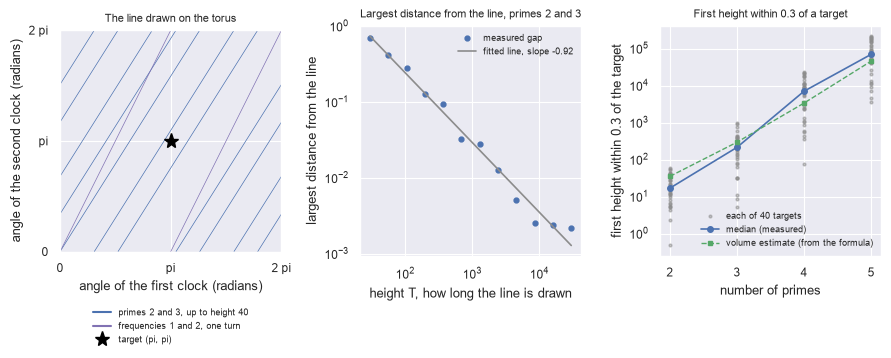

In [11]:
def draw_wrapped_line(axis, frequencies, max_height, color, label):
    heights = np.linspace(0.0, max_height, 40000)
    points = np.mod(np.stack([heights * frequencies[0], heights * frequencies[1]], axis=1), TWO_PI)
    jumps = np.flatnonzero(np.abs(np.diff(points, axis=0)).max(axis=1) > math.pi)
    points = np.insert(points, jumps + 1, np.nan, axis=0)         # break the line where it wraps
    axis.plot(points[:, 0], points[:, 1], color=color, linewidth=0.5, label=label)


figure, (axis_line, axis_gap, axis_height) = plt.subplots(1, 3, figsize=(9.0, 3.4))

draw_wrapped_line(axis_line, LOG_PRIMES[:2], 40.0, NEAREST, "primes 2 and 3, up to height 40")
draw_wrapped_line(axis_line, np.array([1.0, 2.0]), TWO_PI, MODEL, "frequencies 1 and 2, one turn")
axis_line.plot([math.pi], [math.pi], marker="*", markersize=11, color="black", linestyle="none", label="target (pi, pi)")
axis_line.set_xlim(0, TWO_PI)
axis_line.set_ylim(0, TWO_PI)
axis_line.set_aspect("equal")
axis_line.set_xticks([0, math.pi, TWO_PI], ["0", "pi", "2 pi"])
axis_line.set_yticks([0, math.pi, TWO_PI], ["0", "pi", "2 pi"])
axis_line.set_xlabel("angle of the first clock (radians)")
axis_line.set_ylabel("angle of the second clock (radians)")
axis_line.set_title("The line drawn on the torus", fontsize=8)
line_legend = axis_line.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), fontsize=6.5, frameon=False)
for handle in line_legend.legend_handles:
    handle.set_linewidth(1.5)

axis_gap.plot(M1_HEIGHTS, gap_values, marker="o", markersize=3.5, linestyle="none", color=NEAREST, label="measured gap")
axis_gap.plot(M1_HEIGHTS, np.exp(intercept) * M1_HEIGHTS ** slope, color=BEFORE, linewidth=1.2,
              label=f"fitted line, slope {slope:.2f}")
axis_gap.set_xscale("log")
axis_gap.set_yscale("log")
axis_gap.set_xlabel("height T, how long the line is drawn")
axis_gap.set_ylabel("largest distance from the line")
axis_gap.set_title("Largest distance from the line, primes 2 and 3", fontsize=8)
axis_gap.legend(fontsize=6.5, frameon=False)

for count in M3_COUNTS:
    reached_hits = m3_hits[count][np.isfinite(m3_hits[count])]
    axis_height.plot(np.full(reached_hits.size, count), reached_hits, linestyle="none", marker="o", markersize=2,
                     color=BEFORE, alpha=0.5, label="each of 40 targets" if count == M3_COUNTS[0] else None)
measured_counts = [count for count in M3_COUNTS if medians[count] is not None]
axis_height.plot(measured_counts, [medians[count] for count in measured_counts], marker="o", markersize=4,
                 color=NEAREST, linewidth=1.2, label="median (measured)")
axis_height.plot(M3_COUNTS, [estimates[count] for count in M3_COUNTS], marker="s", markersize=3.5,
                 color=BOUND, linewidth=1.0, linestyle="--", label="volume estimate (from the formula)")
axis_height.set_yscale("log")
axis_height.set_xticks(M3_COUNTS)
axis_height.set_xlabel("number of primes")
axis_height.set_ylabel("first height within 0.3 of the target")
axis_height.set_title("First height within 0.3 of a target", fontsize=8)
axis_height.legend(fontsize=6.5, frameon=False, loc="lower right")

figure.tight_layout()
FIGURE_PATH.parent.mkdir(parents=True, exist_ok=True)
figure.savefig(FIGURE_PATH, dpi=160, bbox_inches="tight")
print(f"wrote {FIGURE_PATH.relative_to(ROOT).as_posix()}")

## Summary of the predictions

Each line below is built from the verdicts computed above.

In [12]:
for name, passed in VERDICTS.items():
    print(("[PASS] " if passed else "[FAIL] ") + f"{name}")
print(f"predictions passed: {sum(VERDICTS.values())} of {len(VERDICTS)}")

[PASS] M1
[PASS] M2 control
[PASS] M2 primes
[PASS] M3 factors
[PASS] M3 estimate
predictions passed: 5 of 5
